In [ ]:

import pandas as pd

# Location of our Excel file
file_path = "../data/raw/02_CortexHR_AI_ML_Dataset.xlsx"

# Read the employee dataset
df = pd.read_excel(
    file_path,
    sheet_name="attrition_dataset"
)

# Display the first five rows
df.head()


In [ ]:

# Count rows and columns
rows = df.shape[0]
columns = df.shape[1]

print("Total rows:", rows)
print("Total columns:", columns)
print("Total cells:", df.size)


In [ ]:

# Show all column names
print("Column names:")
print(df.columns.tolist())

# Show the data type of every column
print("\nColumn data types:")
print(df.dtypes)

# Show a summary of the dataset
print("\nDataset information:")
df.info()


In [ ]:

# Count the number of columns of each data type
print(df.dtypes.value_counts())



In [ ]:

# Create a summary of every column
column_summary = pd.DataFrame({
    "Column_Name": df.columns,
    "Data_Type": df.dtypes.astype(str).values,
    "Non_Missing_Values": df.notna().sum().values,
    "Missing_Values": df.isna().sum().values,
    "Unique_Values": df.nunique().values
})

# Display the first rows
column_summary.head(10)


In [ ]:

import os

os.makedirs("../reports", exist_ok=True)

column_summary.to_csv(
    "../reports/column_summary.csv",
    index=False
)

print("Column summary saved successfully!")


In [ ]:

# each column in simple words

descriptions = {
    "row_id": "Row number in the dataset",
    "employee_id": "Unique code for each employee",
    "observation_date": "Date when employee information was recorded",
    "department_id": "Code of the employee's department",
    "role_id": "Code of the employee's job role",
    "job_level": "Employee's job seniority level",
    "work_location": "City where the employee works",
    "work_mode": "Whether the employee works onsite, remotely, or hybrid",
    "employment_type": "Permanent or contract employment",
    "highest_education": "Highest educational qualification",
    "tenure_months": "Number of months the employee has worked here",
    "total_experience_years": "Total work experience in years",
    "previous_employers_count": "Number of previous employers",
    "commute_distance_km": "Distance between home and office in kilometres",
    "annual_fixed_pay": "Employee's annual fixed salary",
    "comp_ratio": "Salary compared with the middle of the salary range",
    "raises_received": "Number of salary increases received",
    "last_raise_pct": "Percentage of the latest salary increase",
    "months_since_last_raise": "Months since the last salary increase",
    "promotions_received": "Number of promotions received",
    "months_since_last_promotion": "Months since the last promotion",
    "internal_transfers": "Number of internal department transfers",
    "last_performance_rating": "Most recent performance rating",
    "last_engagement_score": "Most recent employee engagement score",
    "manager_changes_12m": "Manager changes in the last 12 months",
    "training_hours_12m": "Training hours in the last 12 months",
    "attendance_rate_3m": "Attendance rate over the last three months",
    "late_arrivals_3m": "Number of late arrivals in three months",
    "avg_overtime_hours_per_month_3m": "Average monthly overtime hours",
    "avg_hours_worked_3m": "Average daily working hours",
    "wfh_share_3m": "Share of workdays spent working from home",
    "unpaid_leave_days_6m": "Unpaid leave days in six months",
    "paid_leave_days_6m": "Paid leave days in six months",
    "dept_attrition_rate_prior_12m": "Previous attrition rate of the department",
    "left_within_12m": "Target: whether the employee left within 12 months",
    "voluntary_left_within_12m": "Whether the employee left voluntarily",
    "source": "Source from which the record originated",
    "exit_date": "Employee's last working date",
    "resignation_date": "Date the employee submitted a resignation",
    "exit_reason": "Recorded reason for leaving",
    "exit_interview_done": "Whether an exit interview was completed",
    "fnf_settlement_amount": "Final settlement amount paid when leaving"
}

# Convert the dictionary into a table
data_dictionary = pd.DataFrame({
    "Column_Name": df.columns,
    "Data_Type": df.dtypes.astype(str).values,
    "Meaning": [descriptions.get(col, "Meaning needs review") for col in df.columns]
})

# Save the data dictionary
data_dictionary.to_csv(
    "../reports/data_dictionary.csv",
    index=False
)

data_dictionary


In [ ]:

# Count missing values in each column

missing_count = df.isnull().sum()

# Calculate percentage of missing values
missing_percentage = (missing_count / len(df)) * 100

# Put the results into a table
missing_table = pd.DataFrame({
    "Column_Name": df.columns,
    "Missing_Count": missing_count.values,
    "Missing_Percentage": missing_percentage.values
})

# Show columns that have missing values first
missing_table = missing_table.sort_values(
    by="Missing_Percentage",
    ascending=False
)

display(missing_table)


In [ ]:
import os

os.makedirs("../reports", exist_ok=True)

missing_table.to_csv(
    "../reports/missing_values_report.csv",
    index=False
)

print("Missing-value report saved successfully!")

In [ ]:

# Make an initial decision for every column

leakage_columns = [
    "exit_date",
    "resignation_date",
    "exit_reason",
    "exit_interview_done",
    "fnf_settlement_amount",
    "voluntary_left_within_12m"
]

decisions = []

for column in df.columns:

    missing_percent = (
        df[column].isnull().sum() / len(df)
    ) * 100

    if column in leakage_columns:
        decision = "Exclude from prediction features"

    elif column == "left_within_12m":
        decision = "Check missing target; exclude unknown labels"

    elif missing_percent == 0:
        decision = "Keep; no missing values"

    elif missing_percent > 40:
        decision = "Flag and investigate; consider dropping"

    elif df[column].dtype == "object":
        decision = "Fill with Unknown if appropriate"

    else:
        decision = "Consider median imputation"

    decisions.append(decision)

# Add decisions to the report
missing_table["Decision"] = decisions

display(missing_table)

missing_table.to_csv(
    "../reports/missing_values_report.csv",
    index=False
)

print("Missing-value decisions saved!")


In [23]:

# Check the columns related to salary, hours, and tenure

print(df.columns.tolist())


['row_id', 'employee_id', 'observation_date', 'department_id', 'role_id', 'job_level', 'work_location', 'work_mode', 'employment_type', 'highest_education', 'tenure_months', 'total_experience_years', 'previous_employers_count', 'commute_distance_km', 'annual_fixed_pay', 'comp_ratio', 'raises_received', 'last_raise_pct', 'months_since_last_raise', 'promotions_received', 'months_since_last_promotion', 'internal_transfers', 'last_performance_rating', 'last_engagement_score', 'manager_changes_12m', 'training_hours_12m', 'attendance_rate_3m', 'late_arrivals_3m', 'avg_overtime_hours_per_month_3m', 'avg_hours_worked_3m', 'wfh_share_3m', 'unpaid_leave_days_6m', 'paid_leave_days_6m', 'dept_attrition_rate_prior_12m', 'left_within_12m', 'voluntary_left_within_12m', 'source', 'exit_date', 'resignation_date', 'exit_reason', 'exit_interview_done', 'fnf_settlement_amount']


In [24]:

# IQR method for finding outliers

columns = [
    "annual_fixed_pay",
    "avg_hours_worked_3m",
    "tenure_months"
]

for column in columns:

    # Find the first and third quartiles
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    # Calculate the IQR
    IQR = Q3 - Q1

    # Calculate the lower and upper limits
    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    # Find values outside these limits
    outliers = df[
        (df[column] < lower_limit) |
        (df[column] > upper_limit)
    ]

    print("\nColumn:", column)
    print("Lower limit:", round(lower_limit, 2))
    print("Upper limit:", round(upper_limit, 2))
    print("Number of outliers:", len(outliers))



Column: annual_fixed_pay
Lower limit: -991542.0
Upper limit: 2841498.0
Number of outliers: 94

Column: avg_hours_worked_3m
Lower limit: 7.93
Upper limit: 9.4
Number of outliers: 48

Column: tenure_months
Lower limit: -31.5
Upper limit: 100.5
Number of outliers: 74


In [25]:

# Z-score method for finding outliers

for column in columns:

    # Calculate the average and standard deviation
    mean_value = df[column].mean()
    std_value = df[column].std()

    # Calculate the Z-score for every employee
    z_score = (df[column] - mean_value) / std_value

    # Flag values with a Z-score greater than 3
    outliers = df[z_score.abs() > 3]

    print("\nColumn:", column)
    print("Number of outliers:", len(outliers))



Column: annual_fixed_pay
Number of outliers: 26

Column: avg_hours_worked_3m
Number of outliers: 15

Column: tenure_months
Number of outliers: 42


In [26]:

# Show the 10 highest values in each column

for column in columns:
    print("\nColumn:", column)

    print(
        df[["employee_id", column]]
        .sort_values(by=column, ascending=False)
        .head(10)
    )



Column: annual_fixed_pay
     employee_id  annual_fixed_pay
216     EMP-0433          18671760
85      EMP-0198           5649372
14      EMP-0034           4888200
1746   HIST-1364           4642920
73      EMP-0161           4576800
246     EMP-0479           4480452
988    HIST-0606           4322652
2335   HIST-1953           4256064
1530   HIST-1148           4144368
1603   HIST-1221           4129944

Column: avg_hours_worked_3m
     employee_id  avg_hours_worked_3m
1901   HIST-1519                 9.48
2274   HIST-1892                 9.46
2382   HIST-2000                 9.45
2146   HIST-1764                 9.44
1156   HIST-0774                 9.43
446    HIST-0064                 9.41
2325   HIST-1943                 9.41
2070   HIST-1688                 9.40
1521   HIST-1139                 9.40
1547   HIST-1165                 9.39

Column: tenure_months
     employee_id  tenure_months
0       EMP-0002            164
1       EMP-0004            162
927    HIST-0545       

In [27]:
# Tenure cannot normally be negative
print("Negative tenure records:")

display(
    df.loc[
        df["tenure_months"] < 0,
        ["employee_id", "tenure_months"]
    ]
)

Negative tenure records:


,employee_id,tenure_months
108,EMP-0248,-4
125,EMP-0280,-5
312,EMP-0568,-2
339,EMP-0596,-1


In [28]:

# Create a table comparing both methods

results = []

for column in columns:

    values = df[column].dropna()

    # IQR calculation
    Q1 = values.quantile(0.25)
    Q3 = values.quantile(0.75)
    IQR = Q3 - Q1

    iqr_count = (
        (values < Q1 - 1.5 * IQR) |
        (values > Q3 + 1.5 * IQR)
    ).sum()

    # Z-score calculation
    mean_value = values.mean()
    std_value = values.std()

    if std_value > 0:
        z_scores = (values - mean_value) / std_value
        z_count = (z_scores.abs() > 3).sum()
    else:
        z_count = 0

    results.append({
        "Feature": column,
        "IQR_Outliers": int(iqr_count),
        "Z_Score_Outliers": int(z_count)
    })

outlier_table = pd.DataFrame(results)

display(outlier_table)

import os
os.makedirs("../reports", exist_ok=True)

outlier_table.to_csv(
    "../reports/outlier_comparison.csv",
    index=False
)

print("Outlier comparison saved!")

,Feature,IQR_Outliers,Z_Score_Outliers
0,annual_fixed_pay,94,26
1,avg_hours_worked_3m,48,15
2,tenure_months,74,42


Outlier comparison saved!


In [29]:

# Count employees who left and stayed

print(df["left_within_12m"].value_counts())


left_within_12m
0    2040
1     349
Name: count, dtype: int64


In [30]:

# Count each class
attrition_count = df["left_within_12m"].value_counts()

# Calculate percentages
attrition_percentage = (
    df["left_within_12m"].value_counts(normalize=True) * 100
)

# Create a result table
attrition_table = pd.DataFrame({
    "Employee_Count": attrition_count,
    "Percentage": attrition_percentage
})

# Rename the classes
attrition_table.index = [
    "Stayed" if value == 0 else "Left"
    for value in attrition_table.index
]

display(attrition_table)


,Employee_Count,Percentage
Stayed,2040,85.391377
Left,349,14.608623


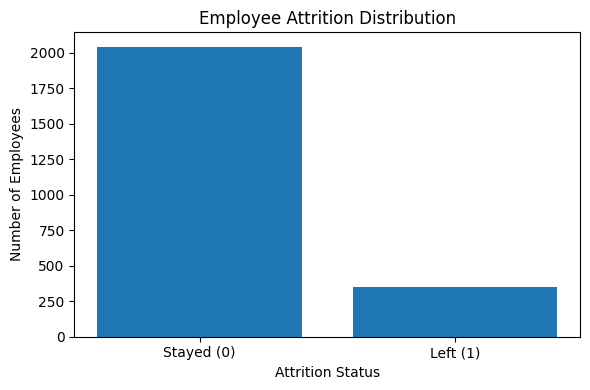

In [31]:

import matplotlib.pyplot as plt

# Count employees in each class
counts = df["left_within_12m"].value_counts().reindex([0, 1], fill_value=0)

# Draw a bar chart
plt.figure(figsize=(6, 4))
plt.bar(
    ["Stayed (0)", "Left (1)"],
    counts.values
)

plt.title("Employee Attrition Distribution")
plt.xlabel("Attrition Status")
plt.ylabel("Number of Employees")
plt.tight_layout()
plt.show()


In [32]:
attrition_table.to_csv(
    "../reports/attrition_distribution.csv"
)

print("Attrition report saved!")

Attrition report saved!


In [33]:
# Columns that could leak the answer
leakage_columns = [
    "exit_date",
    "resignation_date",
    "exit_reason",
    "exit_interview_done",
    "fnf_settlement_amount",
    "voluntary_left_within_12m"
]

# Show which leakage columns exist in the dataset
for column in leakage_columns:
    if column in df.columns:
        print(column, "-> Exclude from prediction features")

exit_date -> Exclude from prediction features
resignation_date -> Exclude from prediction features
exit_reason -> Exclude from prediction features
exit_interview_done -> Exclude from prediction features
fnf_settlement_amount -> Exclude from prediction features
voluntary_left_within_12m -> Exclude from prediction features


In [34]:
import pandas as pd
import os

os.makedirs("../reports", exist_ok=True)

leakage_report = pd.DataFrame({
    "Column_Name": leakage_columns,
    "Decision": ["Exclude from prediction features"] * len(leakage_columns)
})

# Save the report
leakage_report.to_csv(
    "../reports/data_leakage_report.csv",
    index=False
)

print("Leakage report saved successfully!")

Leakage report saved successfully!
